# Bike demand analysis

Question from the case: riders can't find bikes but bikes sit idle elsewhere. Do we need more bikes, or better placement?

Plan:
1. data checks
2. EDA
3. hypothesis test (commute share on working vs non-working days)
4. demand model, trained and tested month by month
5. turn predicted peak demand into a number of bikes

In [1]:
import json
import math

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import PoissonRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, SplineTransformer

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

## 1. Load data and check it

In [2]:
hour = pd.read_csv("../data/hour.csv")
day = pd.read_csv("../data/day.csv")

hour["date"] = pd.to_datetime(hour["dteday"], format="%d-%m-%Y")
day["date"] = pd.to_datetime(day["dteday"], format="%d-%m-%Y")
hour["timestamp"] = hour["date"] + pd.to_timedelta(hour["hr"], unit="h")

print(hour.shape, day.shape)
hour.head()

(17379, 19) (731, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,date,timestamp
0,1,01-01-2011,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16,2011-01-01,2011-01-01 00:00:00
1,2,01-01-2011,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40,2011-01-01,2011-01-01 01:00:00
2,3,01-01-2011,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32,2011-01-01,2011-01-01 02:00:00
3,4,01-01-2011,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13,2011-01-01,2011-01-01 03:00:00
4,5,01-01-2011,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1,2011-01-01,2011-01-01 04:00:00


In [3]:
print("blank cells:", hour.isna().sum().sum(), day.isna().sum().sum())
print("duplicate rows:", hour.duplicated().sum())
print("cnt == casual + registered:", (hour.cnt == hour.casual + hour.registered).all())
print("hourly sums == daily totals:", (hour.groupby("date").cnt.sum().values == day.cnt.values).all())

cols = ["season", "holiday", "weekday", "workingday"]
print("calendar fields match between files:", (hour.groupby("date")[cols].first() == day.set_index("date")[cols]).all().all())

print("\nweathersit counts:", hour.weathersit.value_counts().sort_index().to_dict())
print("hours with humidity 0:", (hour.hum == 0).sum(), hour.loc[hour.hum == 0, "date"].dt.date.unique())
print("temp vs atemp correlation:", round(hour.temp.corr(hour.atemp), 3))
gap = (hour.atemp * 50 - hour.temp * 41).abs()
print("days where feels-like temp is >15C off:", hour.loc[gap > 15, "date"].dt.date.unique())

# season codes - README says 1 = spring, but the codes change on these dates
print("\nseason changes:", day.loc[day.season.diff() != 0, ["dteday", "season"]].values[:5].tolist())

blank cells: 0 0
duplicate rows: 0
cnt == casual + registered: True
hourly sums == daily totals: True
calendar fields match between files: True

weathersit counts: {1: 11413, 2: 4544, 3: 1419, 4: 3}
hours with humidity 0: 22 [datetime.date(2011, 3, 10)]
temp vs atemp correlation: 0.988
days where feels-like temp is >15C off: [datetime.date(2012, 8, 17)]

season changes: [['01-01-2011', 1], ['21-03-2011', 2], ['21-06-2011', 3], ['23-09-2011', 4], ['21-12-2011', 1]]


Season 1 starts on 21 Dec, so it's actually winter (astronomical seasons), not spring as the README says.

### Missing hours
731 days × 24 = 17,544 hours, but we only have 17,379. Let's see which days are short.

In [4]:
present = hour.groupby("date")["hr"].apply(set)
rows = []
for d in pd.date_range("2011-01-01", "2012-12-31"):
    missing = sorted(set(range(24)) - present.get(d, set()))
    if not missing:
        kind = "complete"
    elif missing == [2] and d in [pd.Timestamp("2011-03-13"), pd.Timestamp("2012-03-11")]:
        kind = "clock change"          # 2am doesn't exist when clocks go forward
    elif len(missing) <= 2 and max(missing) <= 6:
        kind = "night gap"             # probably hours with 0 rentals that weren't logged
    else:
        kind = "long gap"              # outage / event
    rows.append({"date": d, "hours": 24 - len(missing), "missing": missing, "kind": kind})
coverage = pd.DataFrame(rows)

print(coverage.kind.value_counts())
print("min cnt in the data:", hour.cnt.min())
coverage[coverage.kind == "long gap"]

kind
complete        655
night gap        66
long gap          8
clock change      2
Name: count, dtype: int64
min cnt in the data: 1


,date,hours,missing,kind
17,2011-01-18,12,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]",long gap
25,2011-01-26,16,"[3, 4, 18, 19, 20, 21, 22, 23]",long gap
26,2011-01-27,8,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,...",long gap
52,2011-02-22,18,"[0, 1, 2, 3, 4, 5]",long gap
238,2011-08-27,18,"[18, 19, 20, 21, 22, 23]",long gap
239,2011-08-28,17,"[0, 1, 2, 3, 4, 5, 6]",long gap
667,2012-10-29,1,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14...",long gap
668,2012-10-30,11,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]",long gap


Decisions:
- missing hours stay missing, I don't fill them in
- the 8 **long gap** days (incl. Hurricane Sandy, 29-30 Oct 2012) are left out of training and out of the main scores
- `casual` and `registered` are never used as features since they add up to `cnt` (leakage)
- `atemp` dropped (copy of temp, and broken on 2012-08-17)
- weathersit 4 has only 3 rows, so I merge it into 3

In [5]:
long_gap_days = coverage.loc[coverage.kind == "long gap", "date"]

hour["weather"] = hour["weathersit"].clip(upper=3)
hour["hr_wd"] = hour["workingday"].astype(str) + "_" + hour["hr"].astype(str)   # hour x working day, for the GLM

## 2. EDA

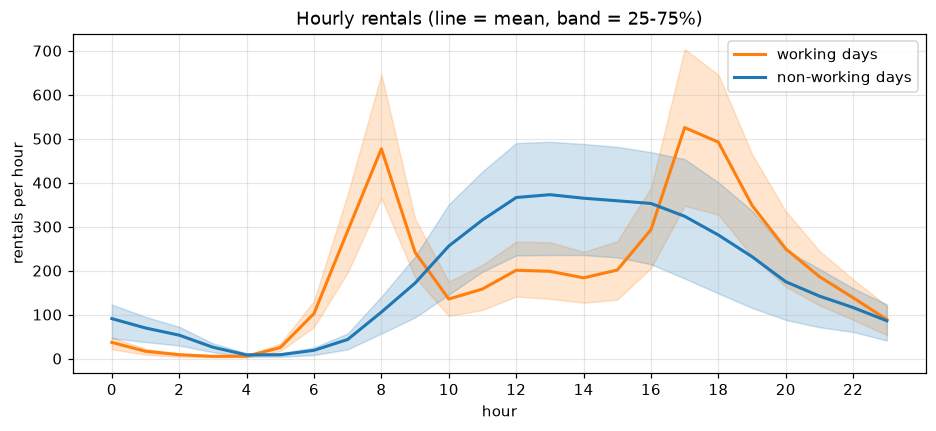

In [6]:
fig, ax = plt.subplots(figsize=(10, 4))
for wd, label, color in [(1, "working days", "tab:orange"), (0, "non-working days", "tab:blue")]:
    g = hour[hour.workingday == wd].groupby("hr")["cnt"]
    ax.plot(g.mean(), color=color, lw=2, label=label)
    ax.fill_between(range(24), g.quantile(0.25), g.quantile(0.75), color=color, alpha=0.2)
ax.set(xlabel="hour", ylabel="rentals per hour", title="Hourly rentals (line = mean, band = 25-75%)", xticks=range(0, 24, 2))
ax.legend()
plt.show()

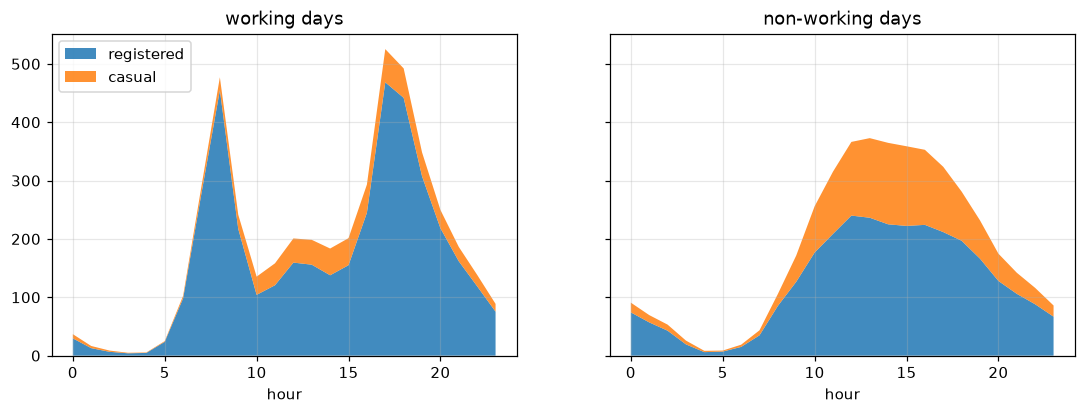

casual share - non-working: 0.317  working: 0.132
registered share overall: 0.812


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, wd, title in [(axes[0], 1, "working days"), (axes[1], 0, "non-working days")]:
    g = hour[hour.workingday == wd].groupby("hr")[["registered", "casual"]].mean()
    ax.stackplot(g.index, g.registered, g.casual, labels=["registered", "casual"], alpha=0.85)
    ax.set(title=title, xlabel="hour")
axes[0].legend(loc="upper left")
plt.show()

s = hour.groupby("workingday")[["casual", "cnt"]].sum()
print("casual share - non-working:", round(s.casual[0] / s.cnt[0], 3), " working:", round(s.casual[1] / s.cnt[1], 3))
print("registered share overall:", round(hour.registered.sum() / hour.cnt.sum(), 3))

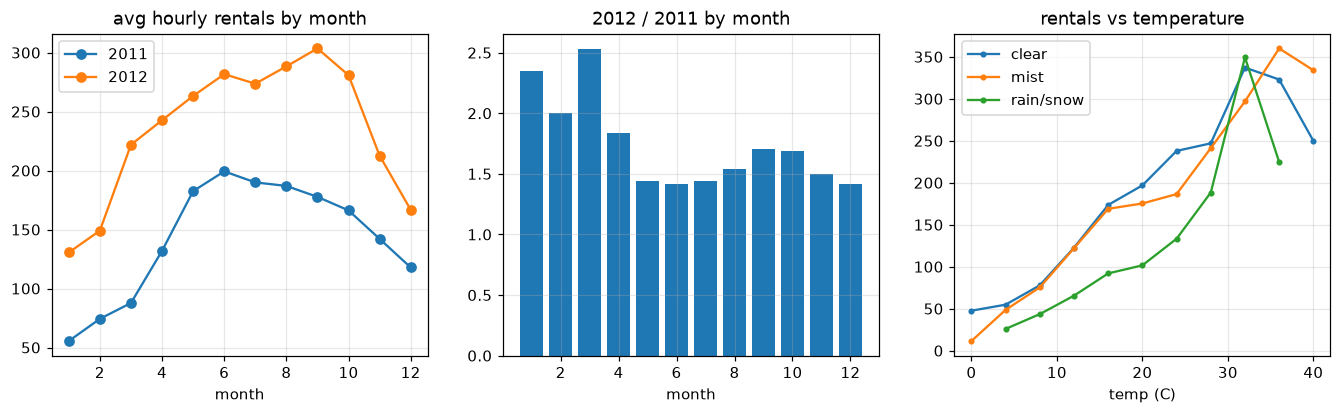

growth 2011 -> 2012: {'cnt': 0.649, 'registered': 0.684, 'casual': 0.508}
{1: 2.35, 2: 2.01, 3: 2.53, 4: 1.84, 5: 1.44, 6: 1.41, 7: 1.44, 8: 1.54, 9: 1.71, 10: 1.69, 11: 1.5, 12: 1.41}


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
m = hour.groupby(["yr", "mnth"])["cnt"].mean().unstack(0)
axes[0].plot(m[0], marker="o", label="2011")
axes[0].plot(m[1], marker="o", label="2012")
axes[0].set(title="avg hourly rentals by month", xlabel="month")
axes[0].legend()

ratio = m[1] / m[0]
axes[1].bar(ratio.index, ratio)
axes[1].set(title="2012 / 2011 by month", xlabel="month")

temp_bins = pd.cut(hour.temp * 41, bins=range(-10, 45, 4))
t = hour.groupby([temp_bins, "weather"], observed=True)["cnt"].mean().unstack()
for w, name in [(1, "clear"), (2, "mist"), (3, "rain/snow")]:
    axes[2].plot([b.mid for b in t.index], t[w], marker=".", label=name)
axes[2].set(title="rentals vs temperature", xlabel="temp (C)")
axes[2].legend()
plt.show()

total = hour.groupby("yr")[["cnt", "registered", "casual"]].sum()
print("growth 2011 -> 2012:", (total.loc[1] / total.loc[0] - 1).round(3).to_dict())
print(ratio.round(2).to_dict())

count    17379.0
mean       189.5
std        181.4
min          1.0
50%        142.0
90%        451.2
95%        563.1
99%        782.2
max        977.0
Name: cnt, dtype: float64


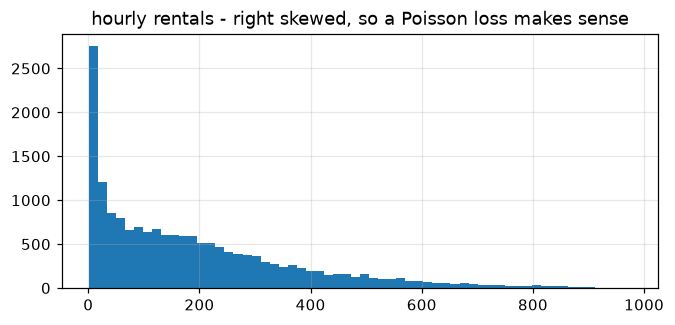

In [9]:
print(hour.cnt.describe(percentiles=[0.5, 0.9, 0.95, 0.99]).round(1))
hour.cnt.hist(bins=60, figsize=(7, 3))
plt.title("hourly rentals - right skewed, so a Poisson loss makes sense")
plt.show()

Takeaways:
- two very different day shapes: commute peaks at 8am and 5-6pm on working days, one midday hump on weekends
- registered users make the commute peaks; casual users are ~32% of rides on non-working days vs 13% on working days
- warmer = more rides (up to ~30C), rain cuts rides at any temperature
- 2012 is ~65% above 2011 and the growth is uneven by month. The data can't tell us why.

## 3. Hypothesis

**H1:** working days have a bigger share of their rides in commute hours (7-9am and 5-7pm, i.e. hours 7,8,9,17,18,19) than non-working days, even after controlling for month and weather.

**H0:** the share is the same or lower on working days.

Why it matters: if demand comes in two short bursts, stations can run empty at 8am even if the city has enough bikes overall.

How I test it:
- one value per day (that day's commute share), since hours from the same day aren't independent
- compare working vs non-working days only inside the same (year-month, weather) group, then take a weighted average of the differences
- p-value: shuffle the working-day labels inside each group 10,000 times
- 95% CI with a bootstrap
- alpha = 0.05

In [10]:
commute_hours = [7, 8, 9, 17, 18, 19]
hour["commute_cnt"] = np.where(hour.hr.isin(commute_hours), hour.cnt, 0)

daily = hour.groupby("date")[["commute_cnt", "cnt"]].sum()
daily["share"] = daily.commute_cnt / daily.cnt
daily = daily.join(day.set_index("date")[["workingday", "weathersit", "yr", "mnth"]])
daily = daily.join(coverage.set_index("date")["kind"])
daily = daily[daily.kind != "long gap"]
daily["group"] = daily.yr.astype(str) + "-" + daily.mnth.astype(str) + "-" + daily.weathersit.astype(str)

print(daily.groupby("workingday")["share"].agg(["count", "mean"]))

            count      mean
workingday                 
0             229  0.260066
1             494  0.517441


In [11]:
def matched_diff(share, wd, group):
    # difference (working - non-working) inside each group, weighted by group size
    t = pd.DataFrame({"share": share, "wd": wd, "group": group})
    means = t.groupby(["group", "wd"])["share"].mean().unstack().dropna()   # groups that have both kinds of day
    sizes = t.groupby("group").size()[means.index]
    return ((means[1] - means[0]) * sizes).sum() / sizes.sum(), sizes.sum()

observed, n_days = matched_diff(daily.share, daily.workingday, daily.group)

rng = np.random.default_rng(0)
groups = [np.flatnonzero(daily.group.values == g) for g in daily.group.unique()]
wd = daily.workingday.values
null = []
for _ in range(10_000):
    shuffled = wd.copy()
    for idx in groups:
        shuffled[idx] = rng.permutation(wd[idx])
    null.append(matched_diff(daily.share.values, shuffled, daily.group.values)[0])
null = np.array(null)
p_value = (1 + (null >= observed).sum()) / (len(null) + 1)

boot = []
for _ in range(2_000):
    idx = np.concatenate([rng.choice(g, size=len(g)) for g in groups])
    s = daily.iloc[idx]
    boot.append(matched_diff(s.share.values, s.workingday.values, s.group.values)[0])
ci = np.percentile(boot, [2.5, 97.5])

print(f"matched difference: {observed * 100:.1f} points  (days used: {n_days})")
print(f"95% CI: {ci[0] * 100:.1f} to {ci[1] * 100:.1f}")
print(f"p-value: {p_value:.4f}   (largest shuffled difference: {null.max() * 100:.1f})")

matched difference: 25.5 points  (days used: 702)
95% CI: 24.7 to 26.1
p-value: 0.0001   (largest shuffled difference: 4.3)


complete days only   25.2 points
2011                 25.6 points
2012                 25.4 points


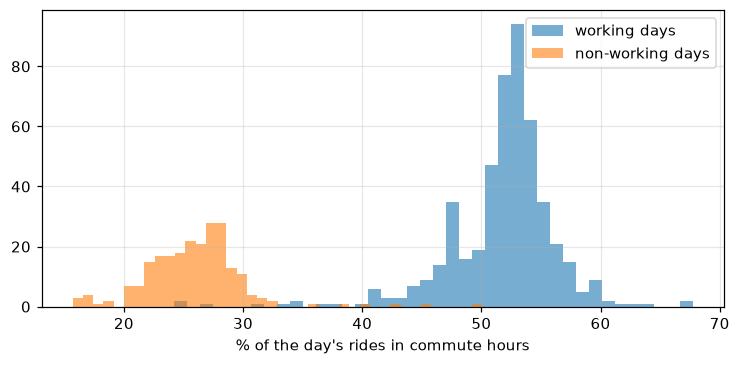

In [12]:
# robustness
for name, mask in [("complete days only", daily.kind == "complete"), ("2011", daily.yr == 0), ("2012", daily.yr == 1)]:
    s = daily[mask]
    print(f"{name:20s} {matched_diff(s.share, s.workingday, s.group)[0] * 100:.1f} points")

plt.figure(figsize=(8, 3.5))
plt.hist(daily[daily.workingday == 1].share * 100, bins=40, alpha=0.6, label="working days")
plt.hist(daily[daily.workingday == 0].share * 100, bins=40, alpha=0.6, label="non-working days")
plt.xlabel("% of the day's rides in commute hours")
plt.legend()
plt.show()

H1 holds clearly: working days put about half their rides into the 6 commute hours vs about a quarter on non-working days, and the gap is the same in every check. This shows *when* demand happens, not *where* (no station data).

## 4. Demand model

Predict rentals per hour from calendar + weather.

Testing setup:
- **month-ahead**: to predict a month, train only on the months before it (no future data, no random split)
- Jul-Sep 2012 = validation, used to pick the model
- Oct-Dec 2012 = test, only looked at once at the end
- pick the model with the lowest RMSE (big errors at busy hours matter most for bike planning)

In [13]:
features = ["hr", "workingday", "holiday", "weekday", "mnth", "yr", "season", "weather", "temp", "hum", "windspeed"]
target = "cnt"


class HourDayMean:
    # baseline: average rentals for each (hour, working day) pair
    def fit(self, X, y):
        self.table = y.groupby([X.hr, X.workingday]).mean()
        return self

    def predict(self, X):
        keys = pd.MultiIndex.from_arrays([X.hr, X.workingday])
        return self.table.reindex(keys).to_numpy()


def poisson_glm(alpha):
    prep = ColumnTransformer([
        ("hour_x_day", OneHotEncoder(drop="first"), ["hr_wd"]),
        ("month_weather", OneHotEncoder(drop="first"), ["mnth", "weather"]),
        ("temp", SplineTransformer(n_knots=5, degree=3), ["temp"]),
        ("rest", "passthrough", ["yr", "hum", "windspeed"]),
    ])
    return Pipeline([("prep", prep), ("glm", PoissonRegressor(alpha=alpha, max_iter=5000))])


def boosting(loss, leaves):
    prep = ColumnTransformer([("features", "passthrough", features)])
    model = HistGradientBoostingRegressor(loss=loss, learning_rate=0.05, max_iter=500, max_leaf_nodes=leaves,
                                          min_samples_leaf=20, early_stopping=False, random_state=0)
    return Pipeline([("prep", prep), ("hgb", model)])


candidates = {"baseline": HourDayMean}
for a in [0.0001, 0.001, 0.01]:
    candidates[f"poisson GLM, alpha={a}"] = lambda a=a: poisson_glm(a)
for loss in ["squared_error", "poisson"]:
    for leaves in [15, 31, 63]:
        candidates[f"boosting, {loss}, {leaves} leaves"] = lambda loss=loss, leaves=leaves: boosting(loss, leaves)

In [14]:
def month_ahead(make_model, months):
    out = []
    for year, month in months:
        start = pd.Timestamp(year, month, 1)
        end = start + pd.offsets.MonthBegin(1)
        train = hour[(hour.date < start) & ~hour.date.isin(long_gap_days)]
        test = hour[(hour.date >= start) & (hour.date < end)]
        model = make_model().fit(train, train[target])
        out.append(pd.DataFrame({"timestamp": test.timestamp.values, "date": test.date.values, "hr": test.hr.values,
                                 "actual": test[target].values, "predicted": np.clip(model.predict(test), 0, None),
                                 "trained_until": str((start - pd.Timedelta(days=1)).date())}))
    return pd.concat(out, ignore_index=True)


def scores(pred):
    p = pred[~pred.date.isin(long_gap_days)]
    err = p.predicted - p.actual
    peaks = p.groupby("date").agg(actual=("actual", "max"), predicted=("predicted", "max"))
    return {"MAE": err.abs().mean(), "RMSE": np.sqrt((err ** 2).mean()),
            "WAPE_%": 100 * err.abs().sum() / p.actual.sum(), "bias": err.mean(),
            "peak_MAE": (peaks.predicted - peaks.actual).abs().mean()}


val_months = [(2012, 7), (2012, 8), (2012, 9)]
test_months = [(2012, 10), (2012, 11), (2012, 12)]

val_preds, val_rows = {}, []
for name, make in candidates.items():
    val_preds[name] = month_ahead(make, val_months)
    val_rows.append({"model": name, **scores(val_preds[name])})
    print(f"{name:35s} RMSE {val_rows[-1]['RMSE']:.1f}")

val_table = pd.DataFrame(val_rows).sort_values("RMSE").round(1)
val_table

baseline                            RMSE 160.8


poisson GLM, alpha=0.0001           RMSE 69.9


poisson GLM, alpha=0.001            RMSE 69.9


poisson GLM, alpha=0.01             RMSE 69.6


boosting, squared_error, 15 leaves  RMSE 57.9


boosting, squared_error, 31 leaves  RMSE 57.0


boosting, squared_error, 63 leaves  RMSE 58.3


boosting, poisson, 15 leaves        RMSE 55.9


boosting, poisson, 31 leaves        RMSE 56.8


boosting, poisson, 63 leaves        RMSE 59.4


,model,MAE,RMSE,WAPE_%,bias,peak_MAE
7,"boosting, poisson, 15 leaves",35.0,55.9,12.1,-15.0,61.8
8,"boosting, poisson, 31 leaves",35.4,56.8,12.3,-15.1,68.4
5,"boosting, squared_error, 31 leaves",36.9,57.0,12.8,-15.6,75.4
4,"boosting, squared_error, 15 leaves",38.1,57.9,13.2,-15.3,71.5
6,"boosting, squared_error, 63 leaves",37.5,58.3,13.0,-16.0,73.8
9,"boosting, poisson, 63 leaves",37.1,59.4,12.9,-16.8,71.4
3,"poisson GLM, alpha=0.01",44.7,69.6,15.5,15.4,70.4
2,"poisson GLM, alpha=0.001",44.7,69.9,15.5,15.8,70.9
1,"poisson GLM, alpha=0.0001",44.7,69.9,15.5,15.8,71.1
0,baseline,119.7,160.8,41.5,-115.3,318.8


In [15]:
best = val_table.iloc[0]["model"]
print("chosen:", best)

test_pred = month_ahead(candidates[best], test_months)
base_pred = month_ahead(candidates["baseline"], test_months)
test_table = pd.DataFrame([{"model": best, **scores(test_pred)}, {"model": "baseline", **scores(base_pred)}]).round(1)
print("\nTest, Oct-Dec 2012:")
print(test_table.to_string(index=False))

all_days = test_pred.copy()
err = all_days.predicted - all_days.actual
print(f"\nincluding the long-gap days: MAE {err.abs().mean():.1f}, WAPE {100 * err.abs().sum() / all_days.actual.sum():.1f}%")
print(f"error reduction vs baseline: {1 - test_table.MAE[0] / test_table.MAE[1]:.0%}")

chosen: boosting, poisson, 15 leaves



Test, Oct-Dec 2012:
                       model  MAE  RMSE  WAPE_%  bias  peak_MAE
boosting, poisson, 15 leaves 37.9  61.0    17.2  -5.1      79.2
                    baseline 78.2 118.5    35.6 -31.5     204.3

including the long-gap days: MAE 38.1, WAPE 17.4%
error reduction vs baseline: 52%


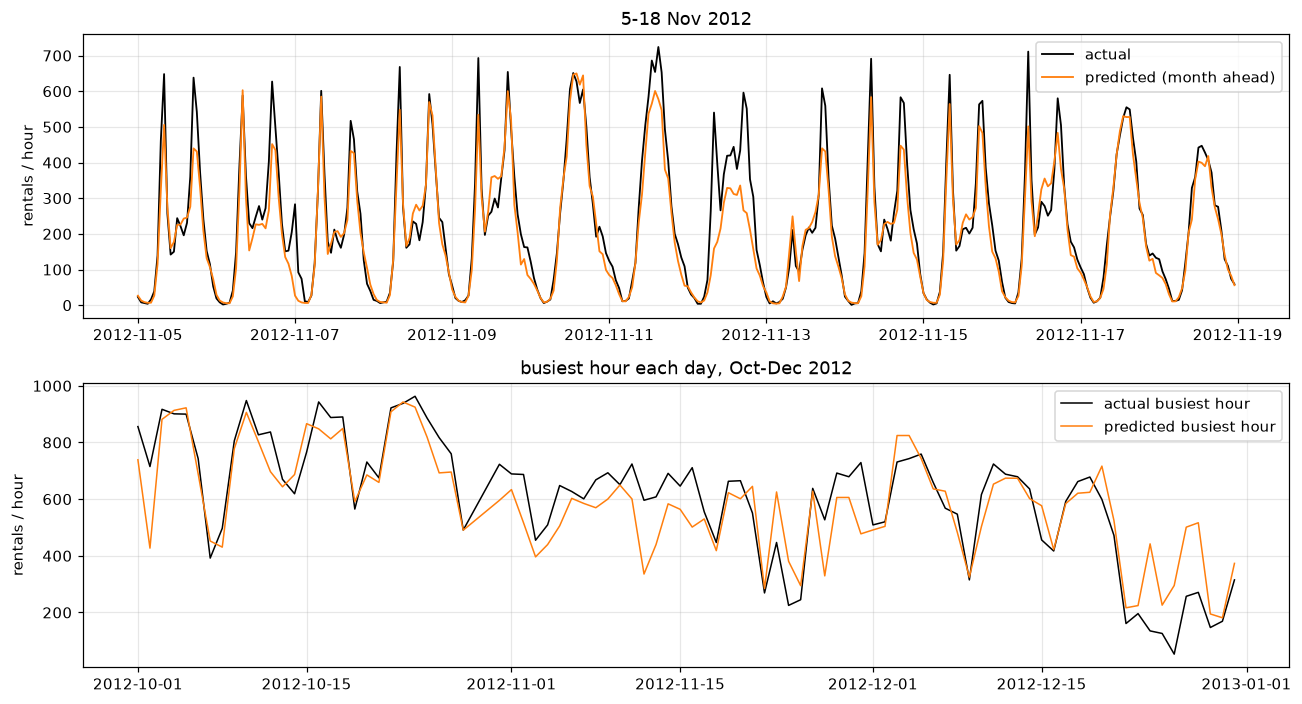

In [16]:
tp = test_pred[~test_pred.date.isin(long_gap_days)]

fig, axes = plt.subplots(2, 1, figsize=(12, 6.5))
two_weeks = tp[(tp.timestamp >= "2012-11-05") & (tp.timestamp < "2012-11-19")]
axes[0].plot(two_weeks.timestamp, two_weeks.actual, color="black", lw=1.2, label="actual")
axes[0].plot(two_weeks.timestamp, two_weeks.predicted, color="tab:orange", lw=1.2, label="predicted (month ahead)")
axes[0].set(title="5-18 Nov 2012", ylabel="rentals / hour")
axes[0].legend()

peaks = tp.groupby("date").agg(actual=("actual", "max"), predicted=("predicted", "max"))
axes[1].plot(peaks.actual, color="black", lw=1, label="actual busiest hour")
axes[1].plot(peaks.predicted, color="tab:orange", lw=1, label="predicted busiest hour")
axes[1].set(title="busiest hour each day, Oct-Dec 2012", ylabel="rentals / hour")
axes[1].legend()
plt.tight_layout()
plt.show()

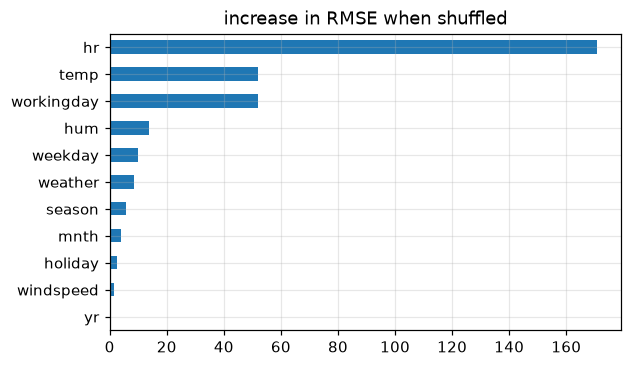

hr            170.7
temp           52.0
workingday     52.0
hum            13.9
weekday         9.9
weather         8.6
season          5.6
mnth            3.9
holiday         2.6
windspeed       1.5
yr              0.0
dtype: float64

In [17]:
# which features matter? (model trained up to Sep, scored on Oct-Dec)
train = hour[(hour.date < "2012-10-01") & ~hour.date.isin(long_gap_days)]
test = hour[(hour.date >= "2012-10-01") & ~hour.date.isin(long_gap_days)]
m = candidates[best]().fit(train, train[target])
imp = permutation_importance(m, test[features], test[target], scoring="neg_root_mean_squared_error", n_repeats=5, random_state=0)
imp = pd.Series(imp.importances_mean, index=features).sort_values()
imp.plot.barh(figsize=(6, 3.5), title="increase in RMSE when shuffled")
plt.show()
imp.sort_values(ascending=False).round(1)

Boosting with Poisson loss wins on validation and roughly halves the baseline error on the test months. Hour dominates, then temperature and working day. (`yr` shows 0 only because it's always 2012 in the test months.)

Weak spots: it runs a bit low on average because demand kept growing during 2012 and trees can't extrapolate, and it can't see events like storms.

Final model = same settings, trained on all usable data. I also save the month-ahead predictions for Jul-Dec 2012, which the app uses.

In [18]:
final_train = hour[~hour.date.isin(long_gap_days)]
final_model = candidates[best]().fit(final_train, final_train[target])

joblib.dump(final_model, "../model/demand_model.joblib")
pd.concat([val_preds[best], test_pred]).to_csv("../model/replay_predictions.csv", index=False)
info = {"model": best, "trained_on_hours": len(final_train),
        "test": scores(test_pred), "baseline_test": scores(base_pred),
        "long_gap_days": [str(d.date()) for d in long_gap_days]}
json.dump(info, open("../model/model_info.json", "w"), indent=2)
print("saved model to ../model/")

saved model to ../model/


## 5. How many bikes?

Rentals aren't bikes, since one bike does many rides a day. What matters is how many bikes are out at the same moment in the busiest hour.

- bikes on the road = rides per hour × trip minutes / 60 (Little's law)
- add a reserve so bikes are waiting where people are: × (1 + reserve)
- some bikes are always in repair: ÷ (1 − broken share)

My assumptions (not in the data): 20 min trips, 25% reserve, 10% broken. Fleet = 2,000 (from the case, fictional).

In [19]:
def bikes_needed(rides_per_hour, trip_min=20, reserve=0.25, broken=0.10):
    on_road = rides_per_hour * trip_min / 60
    return on_road, math.ceil(round(on_road * (1 + reserve) / (1 - broken), 6))


usable = hour[~hour.date.isin(long_gap_days)]
y2012 = usable[usable.yr == 1].cnt
cases = {"median hour": usable.cnt.median(),
         "95th percentile hour, 2012": y2012.quantile(0.95),
         "99th percentile hour, 2012": y2012.quantile(0.99),
         "busiest hour in the data": usable.cnt.max(),
         "busiest predicted hour, test months": tp.predicted.max()}
fleet = pd.DataFrame([(k, v, *bikes_needed(v)) for k, v in cases.items()],
                     columns=["case", "rides_per_hour", "bikes_on_road", "bikes_needed"])
fleet["share_of_2000"] = fleet.bikes_needed / 2000
fleet.round(2)

,case,rides_per_hour,bikes_on_road,bikes_needed,share_of_2000
0,median hour,143.00,47.67,67,0.03
1,"95th percentile hour, 2012",662.95,220.98,307,0.15
2,"99th percentile hour, 2012",835.00,278.33,387,0.19
3,busiest hour in the data,977.00,325.67,453,0.23
4,"busiest predicted hour, test months",942.85,314.28,437,0.22


In [20]:
peak = usable.cnt.max()
grid = pd.DataFrame({f"+{r:.0%} reserve": [bikes_needed(peak, t, r)[1] for t in [10, 15, 20, 30, 45]]
                     for r in [0, 0.25, 0.5, 1.0]}, index=pd.Index([10, 15, 20, 30, 45], name="trip minutes"))
print("bikes needed at the busiest hour, 10% broken:")
print(grid)

on_road = peak * 20 / 60
print(f"\n2,000 bikes only run short if trips average > {2000 * 0.9 / 1.25 / peak * 60:.0f} min,")
print(f"or there are {2000 * 0.9 / on_road:.1f} idle bikes per bike in use,")
print(f"or peak demand grows by {2000 / (on_road * 1.25 / 0.9) - 1:.0%}")

bikes needed at the busiest hour, 10% broken:
              +0% reserve  +25% reserve  +50% reserve  +100% reserve
trip minutes                                                        
10                    181           227           272            362
15                    272           340           408            543
20                    362           453           543            724
30                    543           679           815           1086
45                    815          1018          1222           1629

2,000 bikes only run short if trips average > 88 min,
or there are 5.5 idle bikes per bike in use,
or peak demand grows by 342%


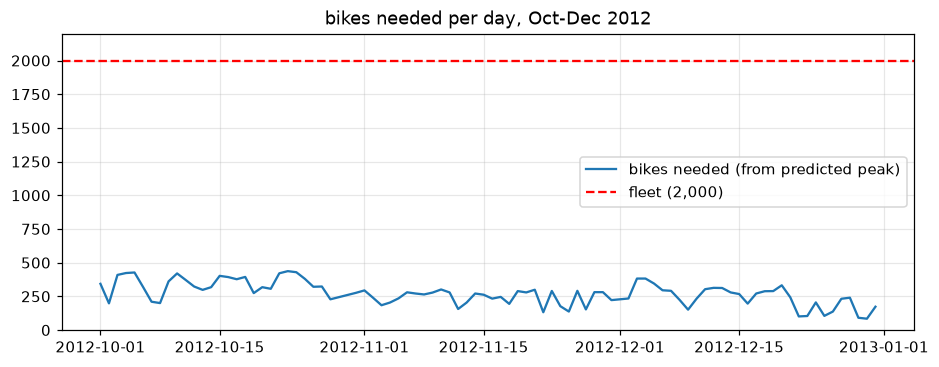

In [21]:
fig, ax = plt.subplots(figsize=(10, 3.5))
daily_need = tp.groupby("date").predicted.max().apply(lambda p: bikes_needed(p)[1])
ax.plot(daily_need, label="bikes needed (from predicted peak)")
ax.axhline(2000, color="red", ls="--", label="fleet (2,000)")
ax.set(ylim=(0, 2200), title="bikes needed per day, Oct-Dec 2012")
ax.legend()
plt.show()

Even the busiest hour in two years needs ~450 bikes under my assumptions, way below 2,000. So a citywide shortage is unlikely. More likely the bikes are in the wrong place at the wrong time, or broken. I can't prove that with this data though: no stations, no failed rentals, no trip times.

**Recommendation:** don't buy bikes first. Use the forecast to move bikes before the peaks, fix broken bikes faster, start collecting station-level data, and run a pilot. Buy only for stations that still run empty afterwards.